# 04 — Phân tích khám phá & trực quan hóa khách hàng rời bỏ Cell2Cell

**Vai trò:** chuyên viên phân tích dữ liệu của công ty viễn thông Cell2Cell.

**Bài toán kinh doanh:** trong mẫu dữ liệu, gần 3 trong 10 khách rời bỏ dịch vụ. Ban giám đốc cần biết:

1. Tình trạng rời bỏ phổ biến đến đâu và gây thiệt hại bao nhiêu?
2. Tín hiệu nào (vòng đời, thiết bị, hành vi dịch vụ, địa lý, nhân khẩu) đi cùng rời bỏ?
3. Ai đang có nguy cơ rời bỏ và nên ưu tiên giữ ai?
4. Nên thử chính sách giữ chân nào?

**Cách chạy:** chạy `python work/viz/prepare_viz_data.py` trước (tạo `work/build/viz_customers.parquet`), sau đó Khởi động lại nhân tính toán → Chạy tất cả các ô.
Mọi biểu đồ được vẽ bằng hàm trong `work/viz/charts.py`, cùng thư viện với bảng điều khiển, nên số liệu trên sổ phân tích và bảng điều khiển luôn khớp.
Tiêu đề mỗi biểu đồ là một **câu kết luận** sinh tự động từ số liệu.

## 1. Thiết lập

In [ ]:
from pathlib import Path
from base64 import b64encode
import json
import sys

from IPython.display import Markdown, display

import pandas as pd

# Tìm thư mục gốc dự án từ thư mục làm việc (chạy được từ root hoặc từ work/viz).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "cell2celltrain.csv").exists())
sys.path.insert(0, str(ROOT / "work" / "viz"))
import charts as c

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)
dashboard_figures = {}

def show(key):
    """Vẽ biểu đồ theo mã trong charts.FIGURES và lưu PNG vào reports/figures."""
    fig = c.FIGURES[key](df)
    dashboard_figures[key] = fig
    image_path = FIG_DIR / f"{key}.png"
    fig.write_image(image_path, width=1000, scale=1.5)
    # Gửi trực tiếp hai định dạng cho Jupyter/VS Code; không phụ thuộc bộ
    # kiểm tra nbformat của fig.show(). PNG vẫn dùng để xem trên GitHub.
    display({
        "application/vnd.plotly.v1+json": json.loads(fig.to_json()),
        "image/png": b64encode(image_path.read_bytes()).decode("ascii"),
    }, raw=True)

## 2. Tổng quan dữ liệu

Nguồn: `data/cell2celltrain.csv`, mỗi dòng là một khách hàng tại một thời điểm quan sát (dữ liệu tại một thời điểm), gồm 58 cột.
Biến mục tiêu **Trạng thái rời bỏ** = Rời bỏ/Ở lại.

In [ ]:
raw = pd.read_csv(ROOT / "data" / "cell2celltrain.csv", na_values=["NA"])
print(f"Dữ liệu nguồn: {c.fmt_n(raw.shape[0])} dòng × {raw.shape[1]} cột · Mã khách hàng trùng: {raw.CustomerID.duplicated().sum()}")
data_types = raw.dtypes.astype(str).map({"int64": "Số nguyên", "float64": "Số thực", "object": "Văn bản"})
display(data_types.value_counts().rename_axis("Kiểu dữ liệu").to_frame("Số cột"))
c.display_table(raw.head())

In [5]:
c.display_table(raw.describe().T[["count", "mean", "50%", "min", "max"]].round(1).head(25))

,Số giá trị,Trung bình,Trung vị,Nhỏ nhất,Lớn nhất
Mã khách hàng,51047.0,3201956.9,3201534.0,3000002.0,3399994.0
Doanh thu tháng,50891.0,58.8,48.5,-6.2,1223.4
Phút gọi mỗi tháng,50891.0,525.7,366.0,0.0,7359.0
Phí định kỳ,50891.0,46.8,45.0,-11.0,400.0
Cuộc gọi qua tổng đài hỗ trợ,50891.0,0.9,0.2,0.0,159.4
Phút vượt gói,50891.0,40.0,3.0,0.0,4321.0
Cuộc gọi chuyển vùng,50891.0,1.2,0.0,0.0,1112.4
Thay đổi phút gọi,50680.0,-11.5,-5.0,-3875.0,5192.0
Thay đổi doanh thu,50680.0,-1.2,-0.3,-1107.7,2483.5
Cuộc gọi bị rớt,51047.0,6.0,3.0,0.0,221.7


## 3. Xử lý dữ liệu

Các bước trong `work/viz/prepare_viz_data.py` (không sửa file nguồn):

| Bước | Xử lý | Lý do |
|---|---|---|
| Giá trị thiếu | Chuỗi `NA` → giá trị thiếu. Cột số giữ giá trị thiếu; cột phân loại → `Không rõ` | Giá trị thiếu rất ít (≤ 1,8%/cột), xóa dòng sẽ làm sai mẫu số |
| Biến mục tiêu | **Trạng thái rời bỏ** Rời bỏ/Ở lại → **Rời bỏ** 1/0; dừng nếu có giá trị lạ | Tính tỷ lệ rời bỏ = trung bình **Rời bỏ** |
| Vùng | **Vùng** = 3 ký tự đầu **Mã vùng phục vụ** (VD `NYC`, `LAX`) | 700+ mã vùng chi tiết quá nhỏ để so sánh |
| Phân nhóm | Chia nhóm thời gian sử dụng, tuổi máy, cuộc gọi CSKH, cuộc gọi rớt, vượt gói, phút gọi; ngưỡng công khai | So sánh tỷ lệ rời bỏ giữa các nhóm có nghĩa kinh doanh |
| Giá trị âm | Loại dòng có giá trị âm ở đúng ba cột: tuổi thiết bị, doanh thu tháng và phí định kỳ | Đếm trên dữ liệu nguồn; dòng âm ở nhiều cột chỉ bị loại một lần |
| Giá trị ngoại lệ | Giữ nguyên; chỉ cắt 1% lớn nhất khi vẽ biểu đồ phân bố cho dễ nhìn | Không có quy tắc nghiệp vụ để loại |
| Phân khúc | **Phân khúc hành động** theo quy tắc ưu tiên (mục 9) | Đầu vào cho chính sách giữ chân |
| Điểm rủi ro | Ghép **Điểm rủi ro**, **Nhóm rủi ro** từ bước phân tích 03 (CatBoost, dự đoán ngoài mẫu) | Dùng lại kết quả có sẵn, không huấn luyện lại |

In [ ]:
df = pd.read_parquet(ROOT / "work" / "build" / "viz_customers.parquet")

# Đếm trên dữ liệu nguồn vì file đã xử lý có thể đã được lọc trước đó.
negative_columns = ["CurrentEquipmentDays", "MonthlyRevenue", "TotalRecurringCharge"]
negative_values = raw[negative_columns].lt(0)
negative_counts = negative_values.sum()
for column in negative_columns:
    print(f"{column}: {c.fmt_n(negative_counts[column])} giá trị âm.")
negative_rows = negative_values.any(axis=1)
negative_ids = raw.loc[negative_rows, "CustomerID"]
df = df.loc[~df.CustomerID.isin(negative_ids)].copy()
assert not df[negative_columns].lt(0).any().any()
print(f"Tổng số dòng bị loại từ nguồn: {c.fmt_n(negative_rows.sum())} (không cộng trùng giữa các cột).")

k = c.kpis(df)
print(f"Bảng phân tích: {c.fmt_n(len(df))} khách · {c.fmt_n(k['churners'])} khách rời bỏ · tỷ lệ rời bỏ {c.fmt_pct(k['rate'], 2)}")
print("Có điểm rủi ro:", "Có" if "RiskDecile" in df else "Không")
c.display_table(df[["TenureBand", "EquipmentAgeBand", "CareCallsBand", "DroppedBand", "OverageBand", "MinutesBand", "ActionSegment"]].describe())

### C02 — Dữ liệu thiếu ở đâu?

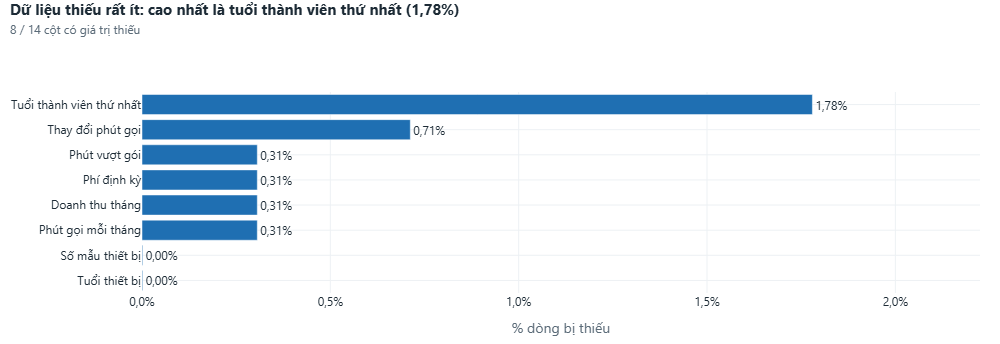

In [9]:
show("C02_du_lieu_thieu")

**Nhận xét:** dữ liệu khá sạch. Cột thiếu nhiều nhất là **Tuổi thành viên thứ nhất** (1,78%); nhóm cột mức sử dụng và doanh thu thiếu 0,31% (156 khách, cùng một nhóm). Vì vậy giữ toàn bộ 51.047 khách, mỗi biểu đồ chỉ loại giá trị thiếu của chính cột đang xét.

## 4. Tổng quan tình trạng rời bỏ

### C01 — Tình trạng rời bỏ phổ biến đến đâu?

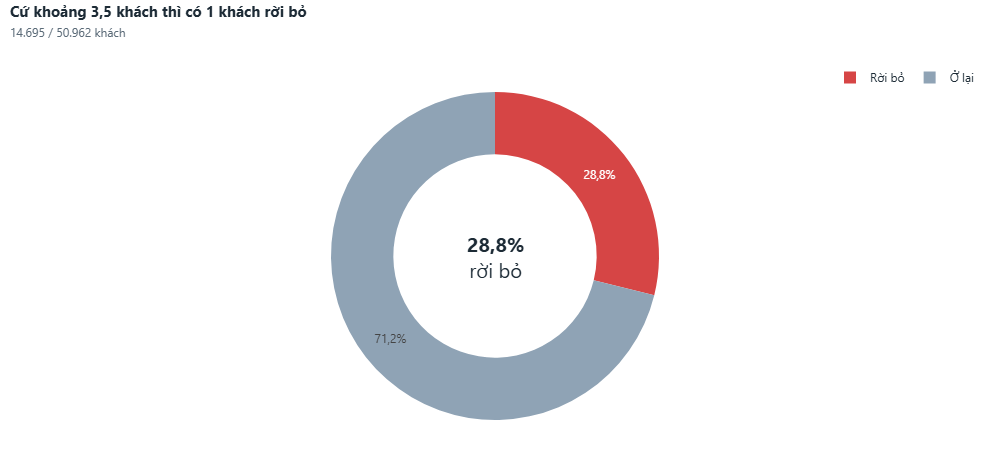

In [11]:
show("C01_ty_le_churn")

**Nhận xét:** 14.711 / 51.047 khách rời bỏ (**28,8%**), cứ khoảng 3,5 khách thì có 1 khách đi. Doanh thu hàng tháng của nhóm đã rời bỏ khoảng **$849 nghìn**. Dữ liệu mất cân bằng vừa phải (71/29) nên mọi so sánh dùng tỷ lệ rời bỏ, không dùng số tuyệt đối.

### C03 — Phân bố tuổi thiết bị khác nhau thế nào giữa hai nhóm?

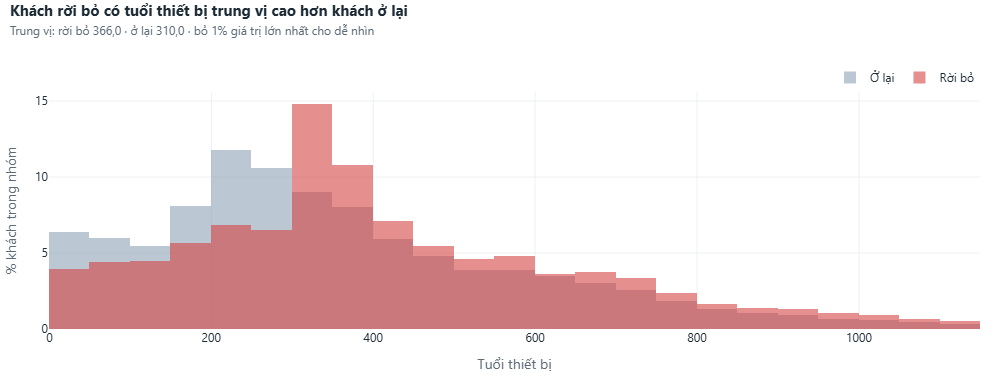

In [13]:
show("C03_phan_bo_tuoi_may")

**Nhận xét:** trung vị tuổi máy của khách rời bỏ là **366 ngày**, của khách ở lại là **310 ngày**. Phân bố của nhóm rời bỏ lệch hẳn về phía máy cũ. Ngược lại, doanh thu trung vị gần như bằng nhau (47,5 so với 48,8 $), nên doanh thu không phân biệt được hai nhóm.

### C04 — Giá trị ngoại lệ và độ phân tán ở các biến chính?

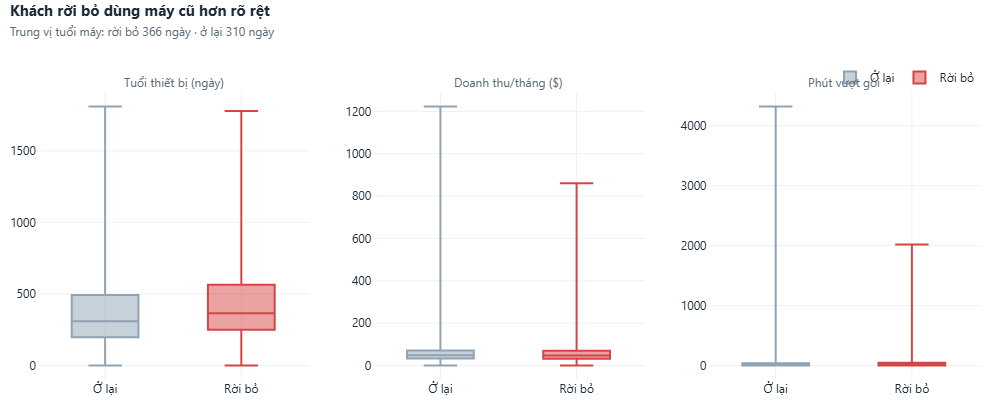

In [15]:
show("C04_box_plot")

**Nhận xét:** cả ba biến đều lệch phải và có nhiều giá trị ngoại lệ (doanh thu > $200, vượt gói > 1.000 phút). Hộp tuổi máy của nhóm rời bỏ dịch hẳn lên trên. Giá trị ngoại lệ được giữ lại vì là khách thật, không phải lỗi.

## 5. Vòng đời và thiết bị

### C05 — Tỷ lệ rời bỏ thay đổi thế nào theo thời gian sử dụng?

In [ ]:
show("C05_vong_doi")
show("C05b_so_khach")

**Nhận xét:** đây là phát hiện quan trọng nhất. Tháng 7–9 rời bỏ chỉ khoảng 15%, rồi **vọt lên 44,6% ở tháng 11 và 40,2% ở tháng 12**, gần gấp 3 lần. Dấu hiệu rõ của việc **hết hợp đồng 1 năm**. Sau tháng 18 rời bỏ quay về quanh mức trung bình. → Cửa sổ giữ chân là tháng 10–13, phải liên hệ **trước** tháng 11.

### C06 — Tuổi thiết bị ảnh hưởng ra sao?

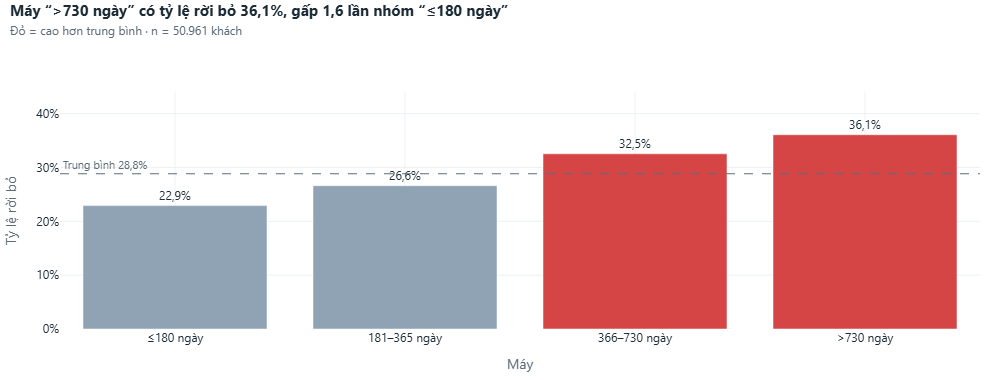

In [21]:
show("C06_tuoi_thiet_bi")

**Nhận xét:** rời bỏ tăng đều theo tuổi máy: ≤180 ngày **22,9%** → 181–365 ngày 26,6% → 366–730 ngày 32,5% → >730 ngày **36,1%**. Đây là biến dạng số tương quan mạnh nhất với rời bỏ (xem C18). → Chính sách đổi máy là đòn bẩy rõ nhất.

### C07 — Thời gian sử dụng và tuổi máy kết hợp thế nào?

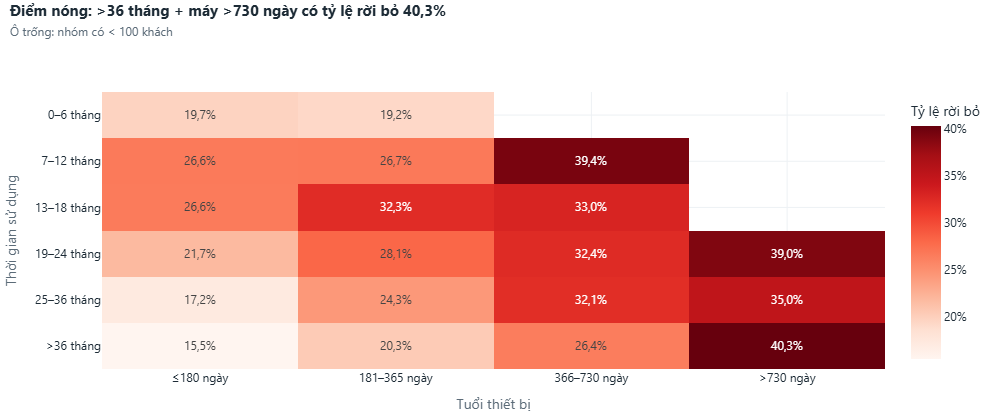

In [23]:
show("C07_heatmap_tenure_thiet_bi")

**Nhận xét:** hai tín hiệu cộng dồn. Khách đã gắn bó lâu (>36 tháng) nhưng dùng máy >2 năm có tỷ lệ rời bỏ **40,3%**, gấp 2,6 lần khách lâu năm dùng máy mới (15,5%). Khách 7–12 tháng mà máy đã 1–2 năm tuổi (nhiều khả năng máy cũ/tân trang khi đăng ký) có tỷ lệ rời bỏ **39,4%**. Ngược lại, máy ≤180 ngày luôn rời bỏ thấp ở mọi thời gian sử dụng.

### C09 — Máy không hỗ trợ mạng hoặc máy tân trang có rời bỏ cao hơn?

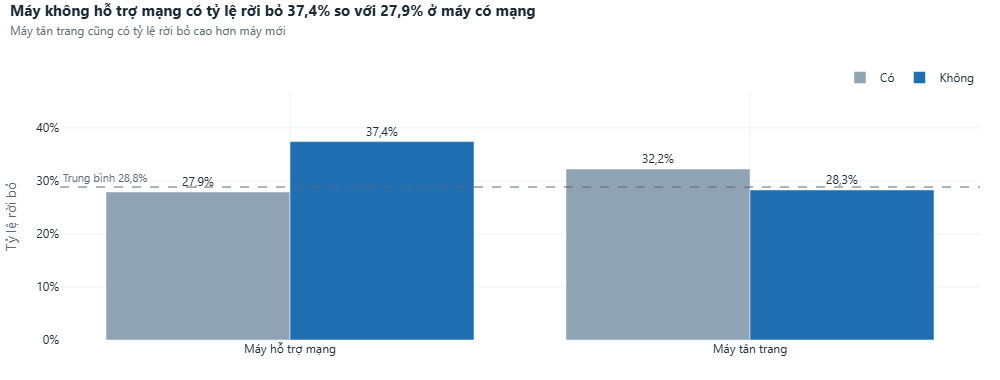

In [25]:
show("C09_dac_diem_thiet_bi")

**Nhận xét:** máy không hỗ trợ mạng có tỷ lệ rời bỏ **37,4%** so với 27,9%; máy tân trang 32,2% so với 28,3%. Khách dùng máy đời cũ, chức năng hạn chế dễ bị đối thủ lôi kéo bằng ưu đãi máy mới.

## 6. Hành vi sử dụng dịch vụ

### C08 — Chương trình giữ chân hiện tại có hiệu quả không?

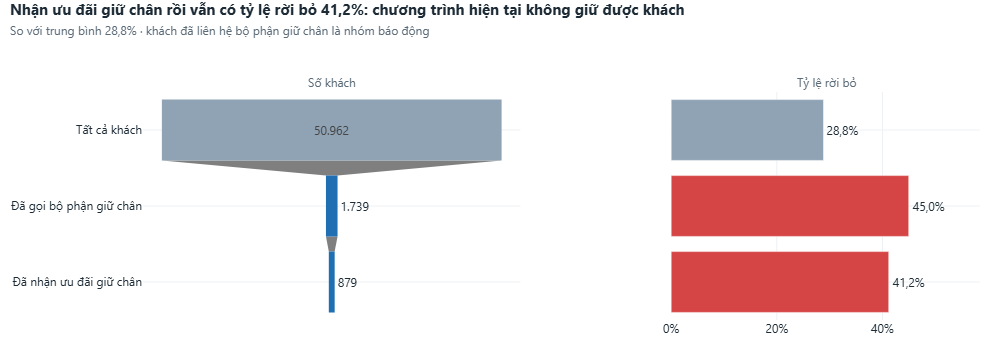

In [27]:
show("C08_retention_funnel")

**Nhận xét:** 1.745 khách đã chủ động gọi bộ phận giữ chân: có tỷ lệ rời bỏ **45,0%**. 881 khách đã nhận ưu đãi giữ chân nhưng vẫn có tỷ lệ rời bỏ **41,1%**, cao hơn hẳn mức trung bình 28,8%. Đây là quan hệ quan sát (khách gọi giữ chân vốn đã muốn đi), nhưng cho thấy ưu đãi hiện tại **không đủ hấp dẫn**. → Nhóm này cần ưu tiên số 1 và ưu đãi cần được thiết kế lại.

### C10 — Gọi chăm sóc khách hàng nhiều có phải dấu hiệu bất mãn?

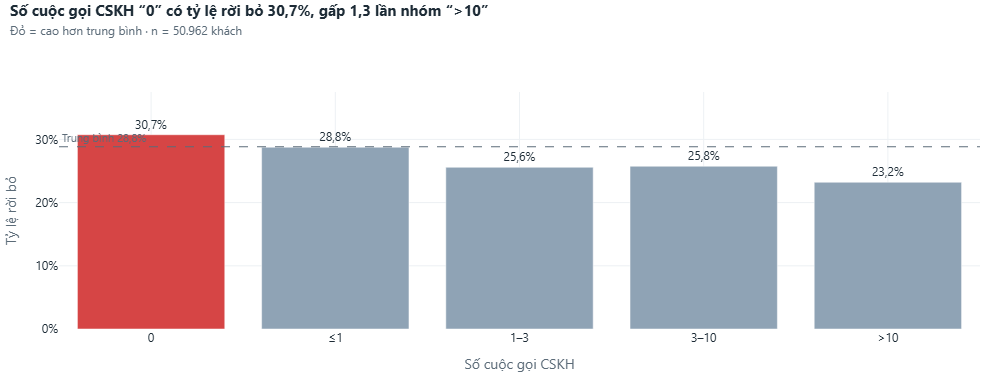

In [29]:
show("C10_goi_cskh")

**Nhận xét:** **nghịch lý:** khách **không** gọi CSKH rời bỏ cao nhất (**30,7%**, 28.020 khách), khách gọi >10 lần/tháng chỉ 23,2%. Khách có tương tác là khách còn quan tâm dịch vụ; khách im lặng mới là khách đã "rời lòng". → Không nên chỉ chờ khiếu nại để phát hiện rủi ro.

### C11 — Chất lượng mạng (cuộc gọi rớt/bị chặn) có gây rời bỏ?

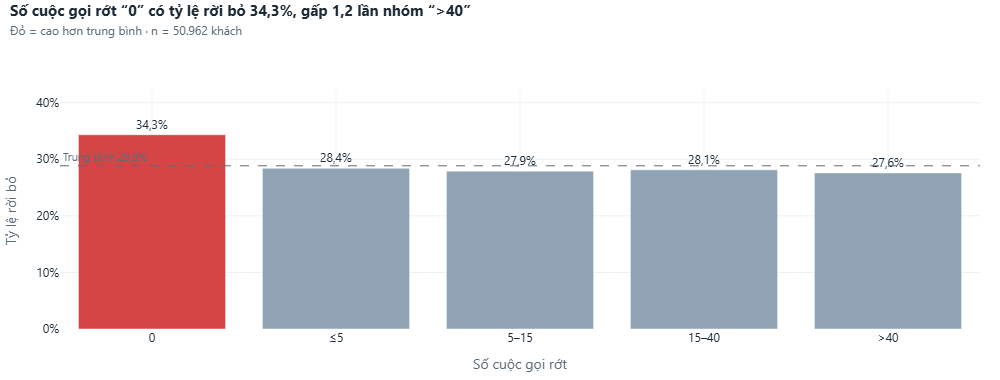

In [31]:
show("C11_cuoc_goi_rot")

**Nhận xét:** khách **không có** cuộc gọi rớt nào lại rời bỏ cao nhất (**34,3%**). Các nhóm còn lại đều quanh 28%. Cuộc gọi rớt = 0 chủ yếu do dùng rất ít, nên đây là tín hiệu **ít sử dụng** chứ không phải mạng tốt. Dữ liệu **không** cho thấy chất lượng mạng là nguyên nhân rời bỏ chính.

### C12 — Gói cước có phù hợp với nhu cầu?

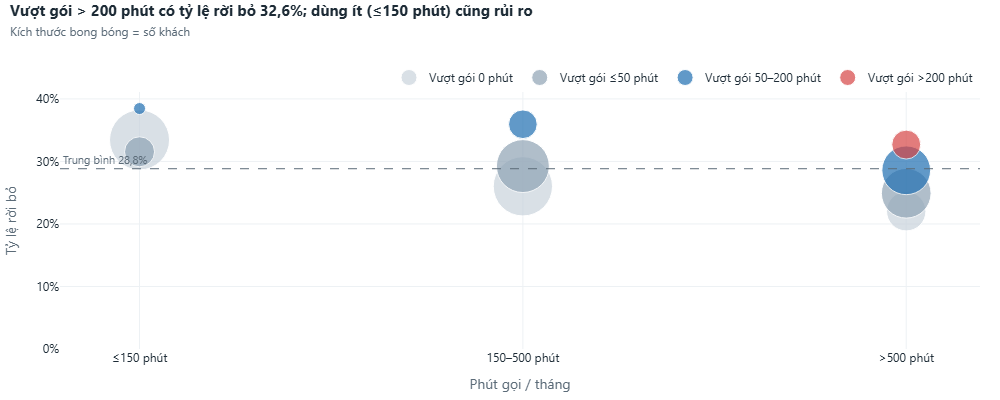

In [33]:
show("C12_goi_cuoc")

**Nhận xét:** hai kiểu lệch gói đều rủi ro. (1) Dùng ít ≤150 phút có tỷ lệ rời bỏ 33,1%: khách ít dùng, thấy gói không đáng tiền. (2) Vượt gói >200 phút có tỷ lệ rời bỏ **32,7%**: khách bị phạt phí vượt, hóa đơn cao. Khách dùng nhiều mà không vượt gói rời bỏ thấp nhất (~22%). → Tư vấn đúng gói là cơ hội giữ chân.

## 7. Địa lý

### C13 — Vùng nào rời bỏ cao nhất?

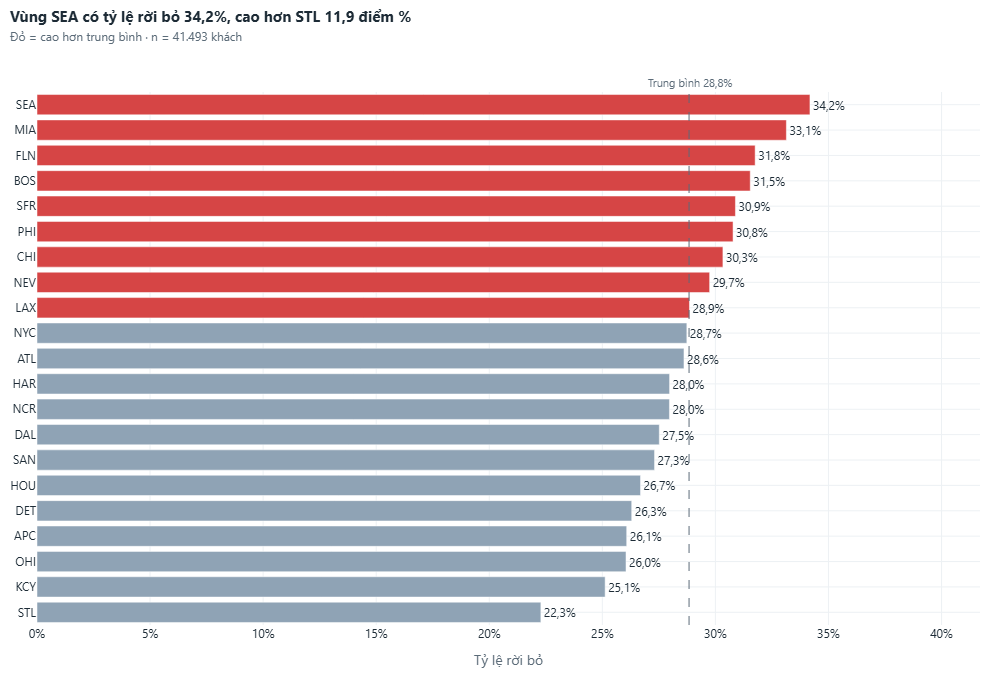

In [35]:
show("C13_vung")

**Nhận xét:** chênh lệch theo vùng đến **11,9 điểm %**: SEA 34,2%, MIA 33,1% so với STL 22,3%, KCY 25,1% (chỉ xét vùng ≥ 800 khách). → Cần xem cạnh tranh và chất lượng dịch vụ tại SEA, MIA, FLN, BOS.

### C14 — Khách rời bỏ tập trung ở đâu về số lượng?

Mặc định hiển thị theo vùng. Bấm vào một vùng để xem các nhóm thời gian sử dụng; bấm “Tất cả” để quay lại. Số trong ô là số khách rời bỏ; rê chuột để xem tỷ lệ và tổng số khách.

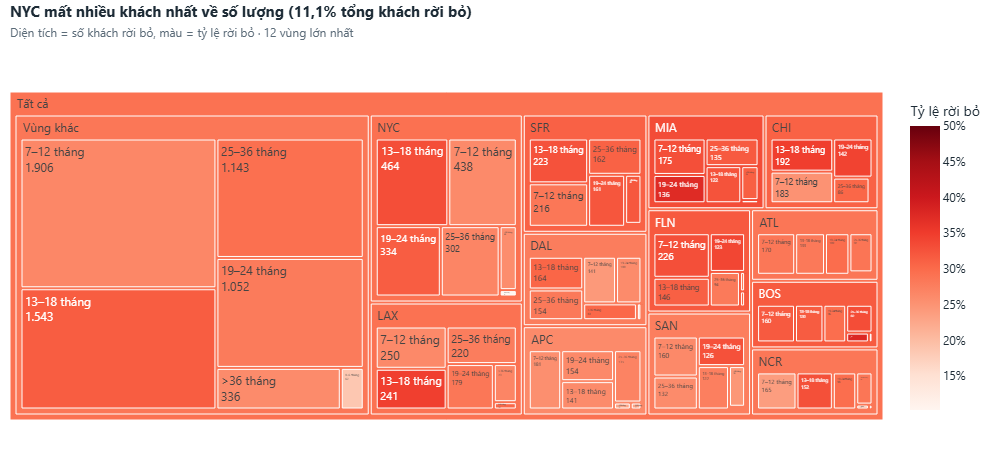

In [37]:
import importlib
c = importlib.reload(c)
show("C14_treemap_vung")

**Nhận xét:** vùng có **tỷ lệ** cao chưa chắc là vùng mất **nhiều khách** nhất. NYC rời bỏ gần mức trung bình nhưng chiếm **11,1%** tổng khách rời bỏ vì quy mô lớn. Trong mỗi vùng, khối 7–18 tháng luôn lớn nhất, khớp với đỉnh hết hợp đồng ở C05.

### C15 — Bao nhiêu vùng chiếm 80% số khách rời bỏ?

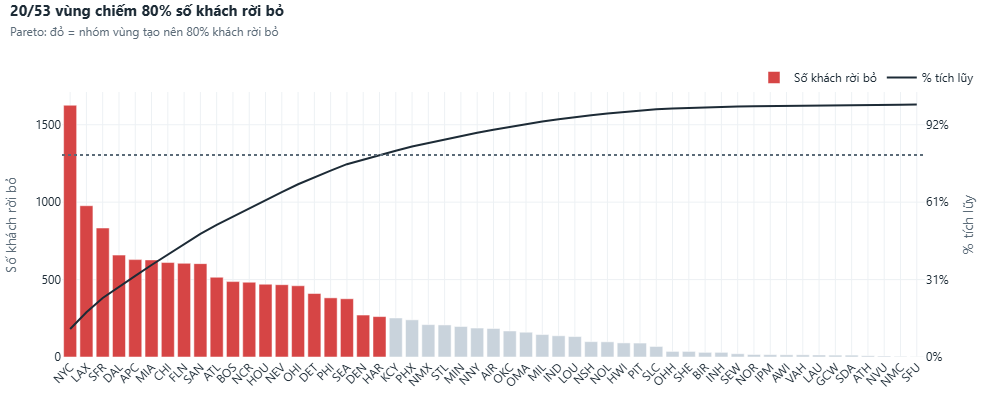

In [39]:
show("C15_pareto_vung")

**Nhận xét:** **20/53 vùng** tạo ra 80% khách rời bỏ. Chiến dịch giữ chân có thể bắt đầu ở nhóm vùng này để có độ phủ cao với chi phí triển khai thấp.

## 8. Đặc điểm khách hàng

### C16 — Hạng tín dụng liên quan thế nào đến rời bỏ?

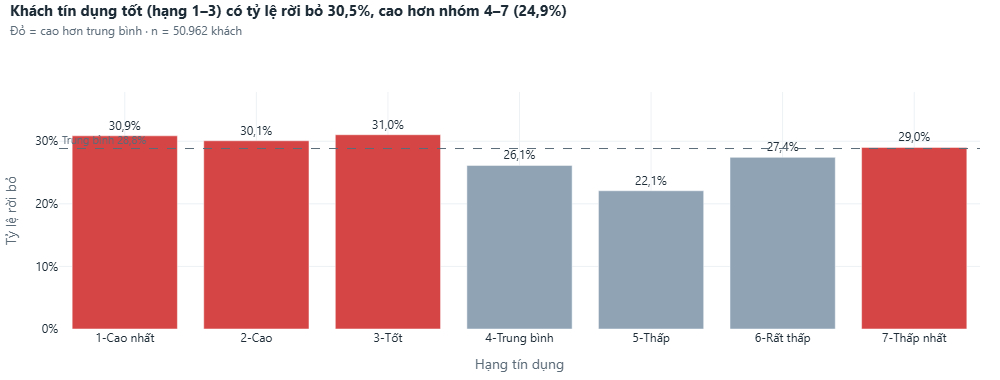

In [41]:
show("C16_tin_dung")

**Nhận xét:** ngược với trực giác: khách tín dụng **tốt** (hạng 1–3) có tỷ lệ rời bỏ **30,5%**, cao hơn nhóm 4–7 (24,9%); thấp nhất là 5-Thấp (22,1%). Giả thuyết: khách tín dụng tốt dễ được đối thủ chấp nhận và mời chào, nên dễ chuyển mạng hơn.

### C17 — Thu nhập, nghề nghiệp, khu vực sống, hôn nhân có quan trọng?

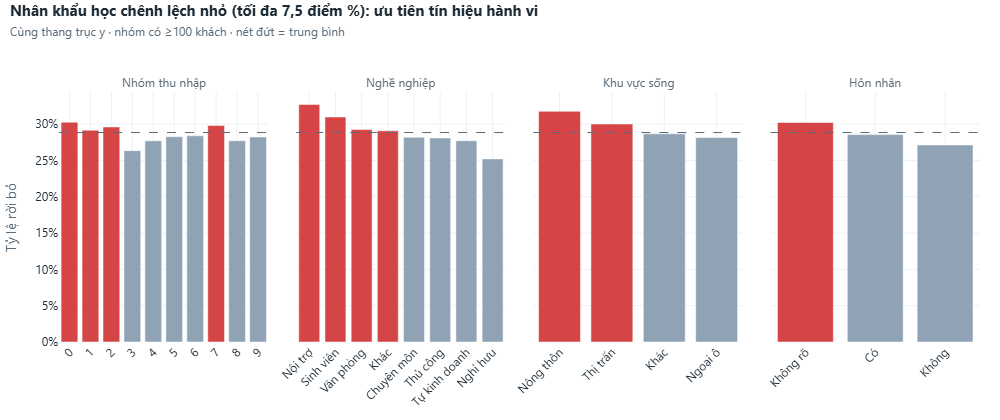

In [43]:
show("C17_nhan_khau_hoc")

**Nhận xét:** chênh lệch nhỏ. Thu nhập và hôn nhân dao động 3–4 điểm %; nghề nghiệp tối đa 7 điểm nhưng nhóm cao nhất (Nội trợ) chỉ có 157 khách. → Nhân khẩu học **không** phải cơ sở tốt để chọn khách can thiệp; nên dùng tín hiệu hành vi và thiết bị.

### C18 — 10 biến chính tương quan với rời bỏ và với nhau như thế nào?

Chỉ xét **10 biến đầu vào của mô hình cũ**: thời gian sử dụng, tuổi thiết bị, hỗ trợ web, doanh thu tháng, phí định kỳ, hạng tín dụng, phút gọi mỗi tháng, thay đổi phút gọi, thay đổi doanh thu và cuộc gọi giờ cao điểm. Thêm nhãn **Rời bỏ** để đối chiếu, tạo ma trận 11 × 11.

**Cách tính:** tương quan Pearson; hỗ trợ web Có = 1, Không = 0; hạng tín dụng từ 1 (cao nhất) đến 7 (thấp nhất). Giá trị thiếu/không rõ được bỏ theo từng cặp biến. Mã hóa chỉ phục vụ biểu đồ này; mô hình đang dùng vẫn giữ 52 biến.

In [ ]:
import importlib
importlib.reload(c)
show("C18_tuong_quan")

In [ ]:
c18_corr = c.correlation_matrix(df)
c18_target = c18_corr[c.TARGET].drop(c.TARGET).dropna()
if not c18_target.empty:
    c18_top = c18_target.abs().idxmax()
    c18_r = f"{c18_target[c18_top]:.2f}".replace(".", ",")
    display(Markdown(
        f"**Nhận xét:** trong **{len(c.C18_FEATURES)} biến chính**, **{c.field_label(c18_top)}** có tương quan tuyến tính "
        f"lớn nhất về độ lớn với rời bỏ (**r = {c18_r}**). "
        "Hệ số mô tả liên hệ tuyến tính, không phải mức độ quan trọng của biến trong CatBoost. "
        "Với hạng tín dụng, số lớn hơn thể hiện hạng thấp hơn."
    ))
else:
    display(Markdown("**Nhận xét:** lát cắt chưa đủ biến thiên để tính tương quan với rời bỏ."))

## 9. Ai cần ưu tiên — mô hình rủi ro và phân khúc hành động

Điểm rủi ro lấy từ bước phân tích 03 (CatBoost, 52 biến, dự đoán ngoài mẫu chia 3 phần đánh giá ngoài mẫu). Ở đây chỉ **diễn giải**, không huấn luyện lại.

### C19a — Điểm rủi ro có phân tầng được khách hàng?

Mỗi nhóm gồm khoảng 10% khách, xếp từ rủi ro thấp đến cao. Cột đỏ có tỷ lệ rời bỏ thực tế vượt đường trung bình của tập khách đang phân tích; cột xanh xám có tỷ lệ bằng hoặc thấp hơn mức này.

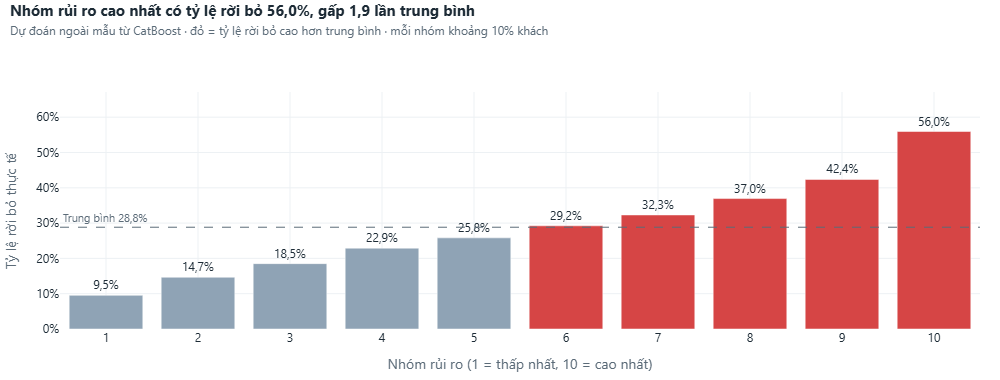

In [47]:
show("C19a_risk_decile")

In [ ]:
risk_groups = c.rate_by(df, "RiskDecile").sort_values("RiskDecile")
display(c.display_table(risk_groups.assign(rate=risk_groups.rate.map(c.fmt_pct))))
highest = risk_groups.iloc[-1]
above_average = risk_groups.loc[risk_groups.rate > c.baseline(df), "RiskDecile"].astype(int)
group_names = ", ".join(above_average.astype(str))
display(Markdown(
    f"**Nhận xét:** nhóm rủi ro {int(highest.RiskDecile)} có tỷ lệ rời bỏ "
    f"**{c.fmt_pct(highest.rate)}**, gấp {c.fmt_ratio(highest.rate / c.baseline(df))} lần trung bình. "
    f"Các nhóm **{group_names}** vượt mức trung bình **{c.fmt_pct(c.baseline(df), 2)}**, nên được tô đỏ. "
    "Màu sắc thể hiện tỷ lệ quan sát thực tế; điểm mô hình dùng để xếp thứ tự các nhóm."
))

### C19b — Với ngân sách hữu hạn, liên hệ bao nhiêu khách là đủ?

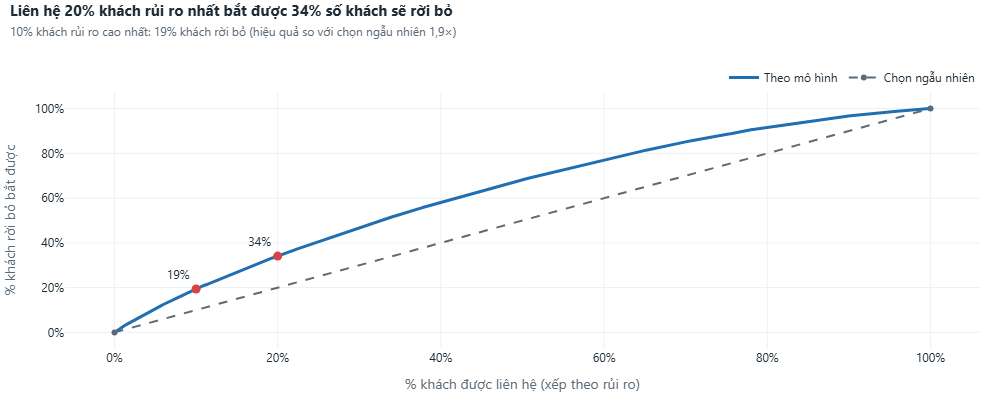

In [49]:
show("C19b_gain_curve")

In [ ]:
ordered = df.sort_values("RiskScore", ascending=False)
total_churners = int(ordered.ChurnFlag.sum())
n10 = max(1, (len(ordered) + 9) // 10)
n20 = max(1, (len(ordered) + 4) // 5)
gain10 = ordered.head(n10).ChurnFlag.sum() / total_churners
gain20 = ordered.head(n20).ChurnFlag.sum() / total_churners
lift10 = ordered.head(n10).ChurnFlag.mean() / c.baseline(df)
display(Markdown(
    f"**Nhận xét:** liên hệ 10% khách có rủi ro cao nhất tiếp cận được **{c.fmt_pct(gain10, 0)}** "
    f"số khách thực tế rời bỏ, hiệu quả gấp **{c.fmt_ratio(lift10)} lần** chọn ngẫu nhiên. "
    f"Liên hệ 20% khách có rủi ro cao nhất tiếp cận được **{c.fmt_pct(gain20, 0)}** số khách rời bỏ."
))

**Quy tắc phân khúc hành động** (**Phân khúc hành động**, xét theo thứ tự, khách khớp quy tắc đầu tiên sẽ thuộc nhóm đó):

| # | Phân khúc | Điều kiện | Căn cứ |
|---|---|---|---|
| 1 | Đã báo động | Đã gọi bộ phận giữ chân | C08 |
| 2 | Hết hợp đồng | Tháng sử dụng 10–13 | C05 |
| 3 | Máy cũ | Máy > 730 ngày, hoặc ≥ 365 ngày và không hỗ trợ mạng | C06, C07, C09 |
| 4 | Rủi ro cao (mô hình) | Còn lại, nhóm rủi ro 8–10 | C19 |
| 5 | Ổn định | Còn lại | |

Trong bản nháp có thử nhóm "Sai gói" (vượt gói > 100 phút) và "Im lặng" (không gọi CSKH và < 150 phút). Sau khi đã tách 3 nhóm đầu,
hai nhóm này rời bỏ **thấp hơn** trung bình (24,3% và 25,1%) nên đã bỏ: tín hiệu của chúng đã nằm trong các nhóm trên.

In [51]:
seg = c.segment_summary(df)
c.display_table(seg.assign(rate=seg.rate.map(c.fmt_pct), revenue_at_risk=seg.revenue_at_risk.map(c.fmt_money),
                           avg_revenue=seg.avg_revenue.round(1)).drop(columns="revenue"))

,Phân khúc hành động,Số khách,Khách rời bỏ,Doanh thu tháng trung bình,Tỷ lệ rời bỏ,Doanh thu tháng bị đe dọa
0,Đã báo động,1739,782,61.6,"45,0%","$47,8 nghìn"
1,Hết hợp đồng,11143,3957,58.1,"35,5%","$229,9 nghìn"
2,Máy cũ,6837,2430,43.6,"35,5%","$104,8 nghìn"
3,Rủi ro cao (mô hình),5555,2385,63.9,"42,9%","$151,5 nghìn"
4,Ổn định,25688,5141,61.9,"20,0%","$317,5 nghìn"


### C20 — Phân khúc nào cần ưu tiên, theo rủi ro và giá trị?

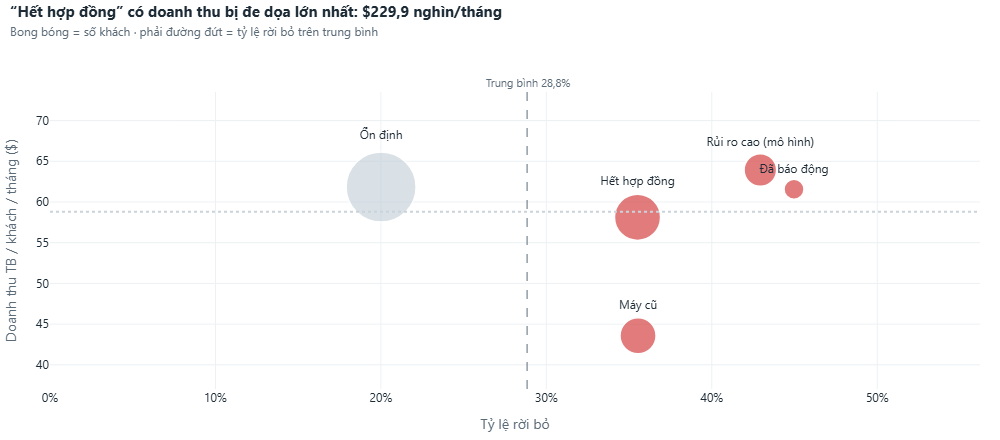

In [52]:
show("C20_phan_khuc")

In [53]:
intervention = seg[seg.ActionSegment != "Ổn định"]
stable = seg[seg.ActionSegment == "Ổn định"]
largest = intervention.loc[intervention.revenue_at_risk.idxmax()]
display(Markdown(
    f"**Nhận xét:** {len(intervention)} nhóm cần can thiệp gồm **{c.fmt_n(intervention.n.sum())} khách** "
    f"({c.fmt_pct(intervention.n.sum() / len(df), 0)} mẫu). Nhóm ổn định có tỷ lệ rời bỏ "
    f"**{c.fmt_pct(stable.rate.iloc[0])}**. Nhóm **{largest.ActionSegment}** có doanh thu tháng bị đe dọa "
    f"lớn nhất: **{c.fmt_money(largest.revenue_at_risk)}**."
))

**Nhận xét:** 4 nhóm cần can thiệp gồm **25.274 khách** (50% mẫu). Nhóm ổn định có tỷ lệ rời bỏ **20,0%**. Nhóm **Hết hợp đồng** có doanh thu tháng bị đe dọa lớn nhất: **$229,9 nghìn**.

### C20b — Nên ưu tiên nhóm nào theo quy mô doanh thu tháng bị đe dọa?

Thanh ngang xếp giảm dần theo **doanh thu tháng bị đe dọa** của các nhóm cần can thiệp. Nhãn cạnh mỗi nhóm ghi số khách và tỷ lệ rời bỏ; nhóm ổn định không nằm trong bảng xếp hạng này.

In [ ]:
# Nạp hai hàm mới nếu kernel đã import charts trước khi file được cập nhật.
import importlib
importlib.reload(c)
show("C20b_uu_tien_doanh_thu")

revenue_priority = c.segment_summary(df)
revenue_priority = revenue_priority[revenue_priority.ActionSegment != "Ổn định"].sort_values("revenue_at_risk", ascending=False)
if not revenue_priority.empty:
    revenue_leader = revenue_priority.iloc[0]
    display(Markdown(
        f"**Nhận xét:** trong các nhóm cần can thiệp, **{revenue_leader.ActionSegment}** đứng đầu theo quy mô doanh thu tháng bị đe dọa: "
        f"**{c.fmt_money(revenue_leader.revenue_at_risk)}**, gồm **{c.fmt_n(revenue_leader.n)} khách**, tỷ lệ rời bỏ **{c.fmt_pct(revenue_leader.rate)}**. "
        "Chỉ số = tổng doanh thu tháng của nhóm × tỷ lệ rời bỏ; đây là quy mô tham khảo, chưa phải doanh thu chắc chắn giữ được."
    ))

### C20c — Nhóm nào có tỷ lệ rời bỏ cao nhất?

Biểu đồ chấm có thân nối (**lollipop**) xếp giảm dần theo **tỷ lệ rời bỏ thực tế**. Chấm càng sang phải, tỷ lệ càng cao; đường đứt là trung bình của toàn bộ mẫu đang xét. Nhóm ổn định được giữ lại làm đối chiếu.

In [ ]:
show("C20c_uu_tien_ty_le")

rate_priority = c.segment_summary(df).sort_values("rate", ascending=False)
if not rate_priority.empty:
    rate_leader = rate_priority.iloc[0]
    display(Markdown(
        f"**Nhận xét:** nhóm **{rate_leader.ActionSegment}** có tỷ lệ rời bỏ cao nhất: **{c.fmt_pct(rate_leader.rate)}**, "
        f"so với trung bình **{c.fmt_pct(c.baseline(df))}**, trên **{c.fmt_n(rate_leader.n)} khách**. "
        "Cách xếp này cho thấy nhóm rời bỏ nhiều nhất theo tỷ lệ; thứ tự có thể khác xếp hạng theo doanh thu ở C20b."
    ))

In [54]:
policies = {
    "Đã báo động": ("Thiết kế lại ưu đãi; chuyên viên cấp cao xử lý trong 24 giờ; ghi nhận lý do rời bỏ", "Tỷ lệ rời bỏ sau 60 ngày; tỷ lệ nhận ưu đãi"),
    "Hết hợp đồng": ("Chăm sóc từ tháng 10; ưu đãi gia hạn 12 tháng trước tháng 11", "Tỷ lệ gia hạn; tỷ lệ rời bỏ tháng 11–13"),
    "Máy cũ": ("Đổi máy trả góp hoặc trợ giá gắn cam kết 12 tháng; ưu tiên máy không hỗ trợ mạng", "Tỷ lệ nhận đổi máy; tỷ lệ rời bỏ sau 90 ngày; chi phí giữ một khách"),
    "Rủi ro cao (mô hình)": ("Khảo sát hài lòng; tư vấn gói phù hợp; ưu đãi cá nhân hóa", "Tỷ lệ rời bỏ sau 90 ngày; doanh thu giữ được"),
    "Ổn định": ("Duy trì chất lượng và chương trình khách hàng thân thiết", "Theo dõi định kỳ"),
}
rows = ["| Phân khúc | Số khách | Tỷ lệ rời bỏ | Chính sách đề xuất | Chỉ số đo hiệu quả |",
        "|---|---:|---:|---|---|"]
for row in seg.itertuples():
    action, metric = policies[str(row.ActionSegment)]
    rows.append(f"| {row.ActionSegment} | {c.fmt_n(row.n)} | {c.fmt_pct(row.rate)} | {action} | {metric} |")
display(Markdown("## 10. Đề xuất chính sách giữ chân\n\n" + "\n".join(rows) +
                 "\n\nƯu tiên triển khai tại các vùng có nhiều khách rời bỏ và tỷ lệ rời bỏ cao. "
                 "Cần thử nghiệm đối chứng ngẫu nhiên trước khi triển khai rộng."))

## 10. Đề xuất chính sách giữ chân

| Phân khúc | Số khách | Tỷ lệ rời bỏ | Chính sách đề xuất | Chỉ số đo hiệu quả |
|---|---:|---:|---|---|
| Đã báo động | 1.739 | 45,0% | Thiết kế lại ưu đãi; chuyên viên cấp cao xử lý trong 24 giờ; ghi nhận lý do rời bỏ | Tỷ lệ rời bỏ sau 60 ngày; tỷ lệ nhận ưu đãi |
| Hết hợp đồng | 11.143 | 35,5% | Chăm sóc từ tháng 10; ưu đãi gia hạn 12 tháng trước tháng 11 | Tỷ lệ gia hạn; tỷ lệ rời bỏ tháng 11–13 |
| Máy cũ | 6.837 | 35,5% | Đổi máy trả góp hoặc trợ giá gắn cam kết 12 tháng; ưu tiên máy không hỗ trợ mạng | Tỷ lệ nhận đổi máy; tỷ lệ rời bỏ sau 90 ngày; chi phí giữ một khách |
| Rủi ro cao (mô hình) | 5.555 | 42,9% | Khảo sát hài lòng; tư vấn gói phù hợp; ưu đãi cá nhân hóa | Tỷ lệ rời bỏ sau 90 ngày; doanh thu giữ được |
| Ổn định | 25.688 | 20,0% | Duy trì chất lượng và chương trình khách hàng thân thiết | Theo dõi định kỳ |

Ưu tiên triển khai tại các vùng có nhiều khách rời bỏ và tỷ lệ rời bỏ cao. Cần thử nghiệm đối chứng ngẫu nhiên trước khi triển khai rộng.

## 11. Tổng kết — 7 nhận xét chính

1. **Tỷ lệ rời bỏ 28,8%** (14.711/51.047 khách), doanh thu tháng của nhóm đã rời bỏ khoảng $849 nghìn.
2. **Đỉnh hết hợp đồng:** rời bỏ vọt từ ~15% (tháng 7–9) lên **44,6%** ở tháng 11, nên cửa sổ giữ chân là tháng 10–13.
3. **Thiết bị là đòn bẩy rõ nhất:** máy > 2 năm có tỷ lệ rời bỏ 36,1%, gấp 1,6 lần máy mới; máy không hỗ trợ mạng 37,4%.
4. **Chương trình giữ chân hiện tại kém hiệu quả:** khách đã nhận ưu đãi vẫn có tỷ lệ rời bỏ 41,1%.
5. **Khách im lặng nguy hiểm hơn khách phàn nàn:** không gọi CSKH có tỷ lệ rời bỏ 30,7%, không có cuộc gọi rớt (ít dùng) có tỷ lệ rời bỏ 34,3%.
6. **Địa lý và tín dụng:** chênh lệch 12 điểm % giữa các vùng; khách tín dụng tốt rời bỏ cao hơn. Nhân khẩu học khác gần như không phân biệt.
7. **Ưu tiên 4 phân khúc** (25.307 khách, có tỷ lệ rời bỏ 35–45%); mô hình giúp nhắm 20% khách bắt được 34% khách rời bỏ.

**Giới hạn:** dữ liệu được ghi nhận tại một thời điểm, các quan hệ là tương quan, không chứng minh nhân quả. **Doanh thu tháng** là doanh thu hiện tại, không phải lợi nhuận hay giá trị vòng đời khách hàng.

## 12. Xuất kết quả cho bảng điều khiển

Lưu các biểu đồ tương tác đã vẽ và dữ liệu của lần phân tích này vào `work/build/dashboard/`. Bảng điều khiển đọc trực tiếp biểu đồ đã xuất khi hiển thị toàn bộ khách hàng; các bộ lọc dùng bản dữ liệu được lưu cùng lần chạy. Sau khi chạy lại sổ phân tích, khởi động lại bảng điều khiển để nạp kết quả mới.

In [56]:
RESULTS_DIR = ROOT / "work" / "build" / "dashboard"
RESULT_FIGURES = RESULTS_DIR / "figures"
RESULT_FIGURES.mkdir(parents=True, exist_ok=True)
for key, figure in dashboard_figures.items():
    figure.write_json(RESULT_FIGURES / f"{key}.json")
df.to_parquet(RESULTS_DIR / "customers.parquet", index=False)
print(f"Đã xuất {len(dashboard_figures)} biểu đồ và {c.fmt_n(len(df))} khách hàng cho bảng điều khiển.")

Đã xuất 22 biểu đồ và 50.962 khách hàng cho bảng điều khiển.
